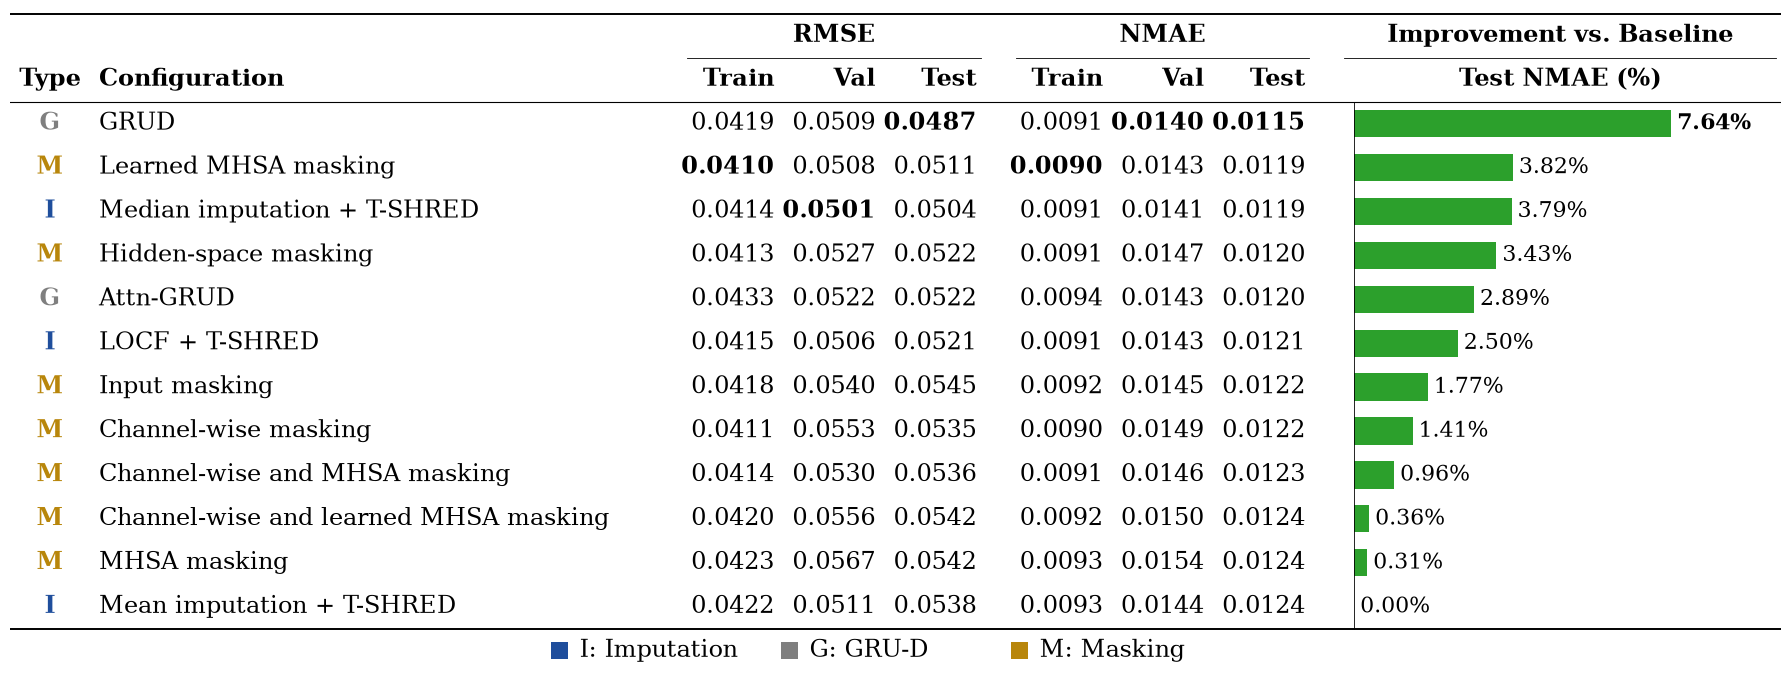

In [4]:
"""Tabella riassuntiva delle metriche di ricostruzione (RMSE / NMAE) per modello.

Colonne: RMSE e NMAE aggregati (Unify all) + NMAE per singolo campo (SE, Uvel, Vvel),
ciascuno con Train / Val / Test, piu' la barra di miglioramento sul test NMAE.
"""
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle

# --------------------------------------------------------------------------- #
# Configurazione
# --------------------------------------------------------------------------- #
METRICS_PATH = "run2.json"
OUT_STEM = "ORESUND_3_table"
SPLITS = ("train", "val", "test")
FONT = 17

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

C_BASE, C_IMPUT, C_MASK, C_GRUD = "#000000", "#1F4E9C", "#B8860B", "#7F7F7F"
C_BAR = "#2ca02c"

GROUPS = {
     #"0": ("B", "Baselines", C_BASE),
    "1": ("I", "Imputation", C_IMPUT),
    "2": ("G", "GRU-D", C_GRUD),
    "3": ("M", "Masking", C_MASK),
}
MODEL_RENAME = {
    "T0A": "Always-available sensors + SHRED",
    "T0B": "Always-available sensors + T-SHRED",
    "T1A": "Median imputation + T-SHRED",
    "T1B": "Mean imputation + T-SHRED",
    "T1C": "LOCF + T-SHRED",
    "T2A": "GRUD",
    "T2B": "Attn-GRUD",
    "T3A": "Input masking",
    "T3B": "Channel-wise masking",
    "T3C": "Hidden-space masking",
    "T3D": "MHSA masking",
    "T3E": "Channel-wise and MHSA masking",
    "T3F": "Learned MHSA masking",
    "T3G": "Channel-wise and learned MHSA masking",
}

# gruppi di colonne numeriche: (titolo sotto-intestazione, prefisso colonna df)
# colonna df = f"{split}-{suffix}"
NUM_GROUPS = [("RMSE", "rmse"), ("NMAE", "nmae")]


# --------------------------------------------------------------------------- #
# Dati
# --------------------------------------------------------------------------- #
def load_dataframe(path):
    """Legge il JSON e restituisce un DataFrame ordinato per test NMAE (unify all)."""
    with open(path, encoding="utf-8") as f:
        data = json.load(f)

    rows = []
    for model, splits in data.items():
        row = {"model": model, "group": model[1]}
        for s in SPLITS:
            agg = splits[s]["Unify all"]
            row[f"{s}-rmse"] = np.sqrt(agg["mse"])
            row[f"{s}-nmae"] = agg["nmae"]
        rows.append(row)

    df = pd.DataFrame(rows).sort_values("test-nmae", kind="stable", ignore_index=True)
    df["name"] = df["model"].map(MODEL_RENAME).fillna(df["model"])
    worst = df["test-nmae"].max()
    df["impr"] = (worst - df["test-nmae"]) / worst * 100
    return df


# --------------------------------------------------------------------------- #
# Utilita' di layout
# --------------------------------------------------------------------------- #
def text_width_in(texts, fontsize=FONT, weight="normal"):
    fig = plt.figure()
    renderer = fig.canvas.get_renderer()
    w = max(
        fig.text(0, 0, t, fontsize=fontsize, fontweight=weight)
        .get_window_extent(renderer).width
        for t in texts
    ) / fig.dpi
    plt.close(fig)
    return w


# --------------------------------------------------------------------------- #
# Disegno
# --------------------------------------------------------------------------- #
def draw_table(df):
    best_impr = df["impr"].max()

    pad = 0.09
    first_col_w = text_width_in(list(df["name"]) + ["Configuration"], weight="bold") + 2 * pad + 0.1
    num_col_w = 0.92 * 1.10
    gap_w = 0.25

    # costruzione delle colonne: [type, config, (3 num + gap) * n_gruppi, barra]
    widths = [0.8, first_col_w]
    group_cols = []                      # lista di liste di indici (train, val, test)
    for _ in NUM_GROUPS:
        start = len(widths)
        widths += [num_col_w] * 3
        group_cols.append([start, start + 1, start + 2])
        widths.append(gap_w)
    widths.append(3.4 * 1.30)
    BAR = len(widths) - 1

    xs = np.concatenate([[0], np.cumsum(widths)[:-1]])
    total_w = float(sum(widths))

    # colonne df corrispondenti a ciascun indice numerico
    col_map = {}
    for (_, suffix), idxs in zip(NUM_GROUPS, group_cols):
        for c, s in zip(idxs, SPLITS):
            col_map[c] = f"{s}-{suffix}"
    best = df[list(col_map.values())].min()
    
    row_h = 0.28 * FONT / 11
    n_rows, header_rows, legend_rows = len(df), 2, 1.0
    fig_h = (n_rows + header_rows + legend_rows + 0.2) * row_h + 0.1
    fig = plt.figure(figsize=(total_w, fig_h))
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(0, total_w)
    ax.set_ylim(n_rows + header_rows + legend_rows + 0.1, -0.1)
    ax.axis("off")

    def put(col, row, text, ha="left", **kw):
        x = {"left": xs[col] + pad,
             "right": xs[col] + widths[col] - pad,
             "center": xs[col] + widths[col] / 2}[ha]
        ax.text(x, row + 0.5, text, ha=ha, va="center", fontsize=FONT, **kw)

    def hline(x0, x1, y, lw):
        ax.plot([x0, x1], [y, y], color="black", lw=lw)

    def span(c0, c1, row, label):
        """Etichetta centrata sulle colonne c0..c1 con sottolineatura."""
        x0, x1 = xs[c0], xs[c1] + widths[c1]
        ax.text((x0 + x1) / 2, row + 0.5, label, ha="center", va="center",
                fontsize=FONT, fontweight="bold")
        hline(x0 + 0.05, x1 - 0.05, row + 1, 0.6)

    # ---- intestazione ----
    # riga 0: titoli dei gruppi di colonne
    for (title, _), idxs in zip(NUM_GROUPS, group_cols):
        span(idxs[0], idxs[-1], 0, title)
    span(BAR, BAR, 0, "Improvement vs. Baseline")
    # riga 1: split
    ax.text(xs[BAR] + widths[BAR] / 2, 1.5, "Test NMAE (%)", ha="center",
            va="center", fontsize=FONT, fontweight="bold")
    put(0, 1, "Type", ha="center", fontweight="bold")
    put(1, 1, "Configuration", fontweight="bold")
    for idxs in group_cols:
        for c, name in zip(idxs, ["Train", "Val", "Test"]):
            put(c, 1, name, ha="right", fontweight="bold")

    # ---- scala delle barre ----
    label_w = 1.0
    bx0 = xs[BAR] + 0.15
    usable = widths[BAR] - 0.15 - label_w - 0.1
    vmin, vmax = min(df["impr"].min(), 0.0), max(best_impr, 1e-9)
    scale = usable / (vmax - vmin)
    zero_x = bx0 - vmin * scale
    bar_h = 0.62

    # ---- corpo ----
    for r, row in df.iterrows():
        y = r + header_rows
        letter, _, color = GROUPS.get(str(row["group"]), ("?", "", "black"))
        put(0, y, letter, ha="center", color=color, fontweight="bold")
        put(1, y, row["name"])
        for c, metric in col_map.items():
            put(c, y, f"{row[metric]:.4f}", ha="right",
                fontweight="bold" if row[metric] == best[metric] else "normal")

        v = row["impr"]
        w = v * scale
        ax.add_patch(Rectangle((min(zero_x, zero_x + w), y + 0.5 - bar_h / 2),
                               abs(w), bar_h, facecolor=C_BAR, edgecolor="none"))
        sign = 1 if v >= 0 else -1
        ax.text(zero_x + w + sign * 0.06, y + 0.5, f"{v:.2f}%",
                ha="left" if v >= 0 else "right", va="center", fontsize=FONT - 1,
                fontweight="bold" if np.isclose(v, best_impr) else "normal")

    ax.plot([zero_x, zero_x], [header_rows, n_rows + header_rows], color="black", lw=0.6)
    hline(0, total_w, 0, 1.4)
    hline(0, total_w, header_rows, 0.8)
    hline(0, total_w, n_rows + header_rows, 1.4)

    # ---- legenda ----
    ly = n_rows + header_rows + legend_rows / 2
    sq, sq_h, entry_w = 0.17, 0.17 / row_h, 2.3
    x_start = (total_w - entry_w * len(GROUPS)) / 2
    for i, (letter, label, color) in enumerate(GROUPS.values()):
        x = x_start + i * entry_w
        ax.add_patch(Rectangle((x, ly - sq_h / 2), sq, sq_h, facecolor=color, edgecolor="none"))
        ax.text(x + sq + 0.12, ly, f"{letter}: {label}", ha="left", va="center", fontsize=FONT)

    return fig


def main():
    df = load_dataframe(METRICS_PATH)
    fig = draw_table(df)
    fig.savefig(f"{OUT_STEM}.png", dpi=500, bbox_inches="tight", pad_inches=0.03)
    plt.show()


if __name__ == "__main__":
    main()